# Student Dropout Prediction — Data Exploration

## Objective
Explore a real-world student academic success dataset
to understand its structure, features, target variable,
data quality, and suitability for machine learning.

**Dataset:** UCI ML Repository — ID 697
**Task:** Multiclass Classification

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [37]:
# Loading the dataset
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")

# FIX: Strip hidden whitespace/tabs from column names and fix the 'Nacionality' typo
df.columns = df.columns.str.strip()
df.rename(columns={"Nacionality": "Nationality"}, inplace=True)

print("Dataset loaded and column names cleaned successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded and column names cleaned successfully!
Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [38]:
# Checking data types, missing values, and duplicates
df.info()

print("\nData Types Summary:")
display(df.dtypes.value_counts())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

int64      29
float64     7
str         1
Name: count, dtype: int64


Total missing values: 0
Duplicate rows: 0


In [39]:
# Explicitly separate integer-encoded categorical features from true numerical features
categorical_cols = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nationality', "Mother's qualification", 
    "Father's qualification", "Mother's occupation", "Father's occupation", 
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 
    'Gender', 'Scholarship holder', 'International'
]

# Note: 'Application order' (0-9) is ordinal, so we keep it with numericals for summary stats
numerical_cols = [col for col in df.columns if col not in categorical_cols and col != 'Target']

print(f"True Numerical Columns ({len(numerical_cols)}):")
for i, col in enumerate(numerical_cols, 1):
    print(f"  {i:02d}. {col}")

print(f"\nCategorical/Binary Columns ({len(categorical_cols)}):")
for i, col in enumerate(categorical_cols, 1):
    print(f"  {i:02d}. {col} ({df[col].nunique()} unique categories)")

True Numerical Columns (19):
  01. Application order
  02. Previous qualification (grade)
  03. Admission grade
  04. Age at enrollment
  05. Curricular units 1st sem (credited)
  06. Curricular units 1st sem (enrolled)
  07. Curricular units 1st sem (evaluations)
  08. Curricular units 1st sem (approved)
  09. Curricular units 1st sem (grade)
  10. Curricular units 1st sem (without evaluations)
  11. Curricular units 2nd sem (credited)
  12. Curricular units 2nd sem (enrolled)
  13. Curricular units 2nd sem (evaluations)
  14. Curricular units 2nd sem (approved)
  15. Curricular units 2nd sem (grade)
  16. Curricular units 2nd sem (without evaluations)
  17. Unemployment rate
  18. Inflation rate
  19. GDP

Categorical/Binary Columns (17):
  01. Marital status (6 unique categories)
  02. Application mode (18 unique categories)
  03. Course (17 unique categories)
  04. Daytime/evening attendance (2 unique categories)
  05. Previous qualification (17 unique categories)
  06. Nationality

In [40]:
# Descriptive statistics ONLY on true numerical features
print("Descriptive Statistics for True Numerical Features:")
display(df[numerical_cols].describe().T.round(2))

Descriptive Statistics for True Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Percentage distribution:
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


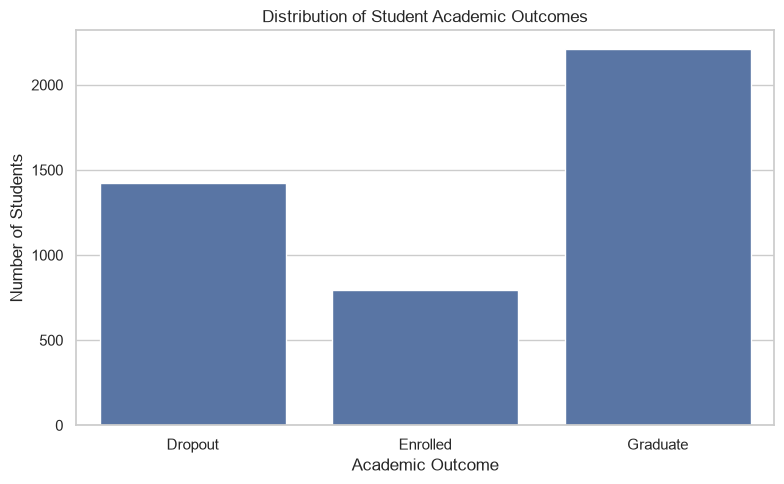

In [27]:
print(df["Target"].value_counts())

print("\nPercentage distribution:")
print(
    df["Target"].value_counts(normalize=True) * 100
)
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Distribution of Student Academic Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show() # before training the modelwe can visualize the class imbalance as below with below chart

#Observations:
#Since the target classess are imbalanced , when evaluating model performance accuracy only will not be enough. We will need to use other metrics like precision, recall, f1-score and confusion matrix to evaluate the model performance


### Target Variable Distribution Analysis

**Objective:** To examine the distribution of the three academic outcome classes and identify potential class imbalance before model training.

**Key Findings:**

The dataset contains 4,424 student records distributed across three academic outcome classes:

- **Graduate:** 2,209 students (49.93%)
- **Dropout:** 1,421 students (32.12%)
- **Enrolled:** 794 students (17.95%)

The Graduate class represents the largest proportion of the dataset, while the Enrolled class has the fewest observations.

**Interpretation:**

The distribution indicates a class imbalance, with the Graduate class accounting for nearly half of all observations. The Enrolled class represents less than one-fifth of the dataset.

This imbalance may influence model performance, as classification algorithms can favor the majority class. Consequently, a model may achieve reasonable overall accuracy while performing poorly on less represented classes.

**Implications for Machine Learning:**

- Use a **stratified train-test split** to preserve approximately the same class proportions in the training and testing datasets.
- Evaluate both Decision Tree and Random Forest models using **accuracy, macro-averaged precision, macro-averaged recall, macro F1-score, and confusion matrices**.
- Examine **per-class precision and recall**, particularly for the Enrolled and Dropout classes.
- Consider class weighting or other imbalance-handling techniques if the baseline models perform poorly on minority classes.
- Use the same training and testing partitions for both algorithms to ensure a fair comparison.

**Conclusion:**

The target distribution reveals a meaningful class imbalance that should be considered during model development and evaluation. Accuracy alone will not provide a complete assessment of classification performance.

In [28]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget classes:")
print(df["Target"].unique())

Rows: 4424
Columns: 37
Missing values: 0
Duplicate rows: 0

Target classes:
<ArrowStringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str


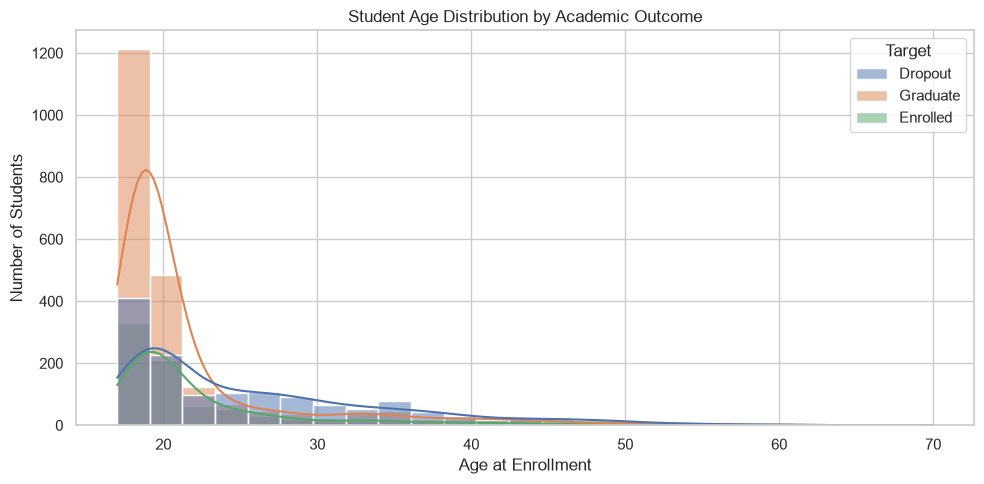

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    hue="Target",
    bins=25,
    kde=True
)

plt.title("Student Age Distribution by Academic Outcome")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()



### Age Distribution by Academic Outcome

**Objective:**

To examine the distribution of students' ages at enrollment and explore potential differences in age patterns across the three academic outcome classes: Dropout, Enrolled, and Graduate.

**Key Findings:**

- Most students are concentrated in the younger age range, approximately between 17 and 22 years.
- The Graduate class shows a particularly high concentration of students around ages 18–20.
- The overall age distribution appears positively skewed (right-skewed), with fewer students in older age groups and a long tail extending toward higher ages.
- The Dropout class appears to have a broader age distribution, with relatively more observations in older age ranges compared with the Graduate class.
- The three classes have overlapping age distributions, suggesting that age alone is unlikely to completely distinguish academic outcomes.

**Interpretation:**

The visualization suggests that age at enrollment may be associated with students' academic outcomes. However, because the histogram displays absolute frequencies and the target classes are imbalanced, differences in counts do not directly establish differences in dropout or graduation rates.

Further analysis using outcome percentages within age groups is necessary to make a more meaningful comparison.

**Implications for Machine Learning:**

- Age at enrollment is a potentially informative numerical feature and should be considered during model training.
- Decision Tree and Random Forest algorithms can learn nonlinear relationships and age-based split thresholds without requiring manual age categorization.
- The observed right-skewed distribution does not, by itself, require normalization or removal of older student observations for tree-based models.
- Age-group analysis will be conducted to further investigate how academic outcome proportions vary across age ranges.

**Conclusion:**

The age distribution reveals noticeable demographic differences across academic outcome classes. While these patterns suggest that age may contribute useful predictive information, further analysis is required before drawing conclusions about age-specific dropout risks.

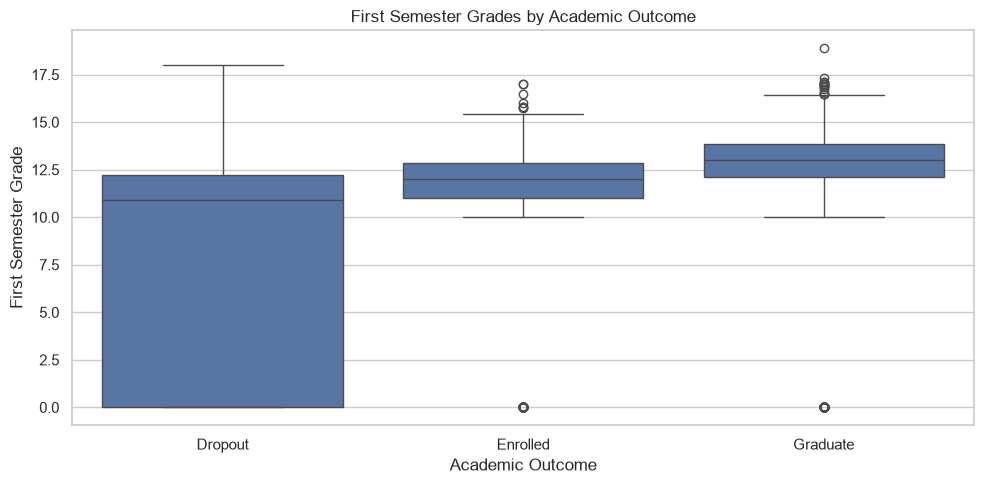

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("First Semester Grades by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("First Semester Grade")

plt.tight_layout()
plt.show()

### First Semester Grade Distribution by Academic Outcome

**Objective:**

To examine differences in first-semester academic performance across the three academic outcome classes and investigate whether academic grades may be informative predictors of student outcomes.

**Key Findings:**

- The Graduate group has the highest observed median first-semester grade (approximately 13).
- The Enrolled group has an intermediate median grade (approximately 12).
- The Dropout group has the lowest median grade (approximately 11) and a substantially wider grade distribution.
- Zero-grade observations are visible across the academic outcome groups, with a particularly pronounced concentration in the Dropout group.
- The grade distributions overlap, indicating that first-semester grades alone do not perfectly distinguish the three academic outcomes.

**Interpretation:**

The boxplot suggests an association between first-semester academic performance and final academic outcomes. Students classified as graduates tend to have higher first-semester grades, whereas students classified as dropouts demonstrate greater variation in academic performance.

The presence of zero-grade observations requires further investigation. These values should not automatically be treated as missing or erroneous, as they may reflect legitimate academic circumstances.

The observed relationships are descriptive and do not establish that first-semester grades directly cause graduation or dropout.

**Implications for Machine Learning:**

- First-semester grade is a potentially informative numerical predictor for both Decision Tree and Random Forest classifiers.
- The observed differences suggest that academic performance features should be evaluated during model training.
- Zero-grade observations should be investigated before making preprocessing decisions.
- Tree-based models can learn grade-based thresholds and nonlinear relationships without requiring feature scaling.
- Since grade distributions overlap, additional demographic, financial, and academic features may improve predictive performance.
- The availability of first-semester grades at the intended prediction time must be considered to avoid temporal data leakage.

**Conclusion:**

The analysis indicates that first-semester academic performance is associated with academic outcomes. Graduate students generally exhibit higher grades, while dropout students demonstrate greater variability. Further statistical analysis is required to verify the exact differences and understand the concentration of zero-grade observations.

Age Group
<20      1952
20-24    1334
25-29     427
30-39     463
40+       248
Name: count, dtype: int64

Target,Dropout,Enrolled,Graduate
Age Group,,,
<20,20.95,16.96,62.09
20-24,28.56,22.56,48.88
25-29,57.61,16.86,25.53
30-39,55.72,12.96,31.32
40+,51.21,12.10,36.69


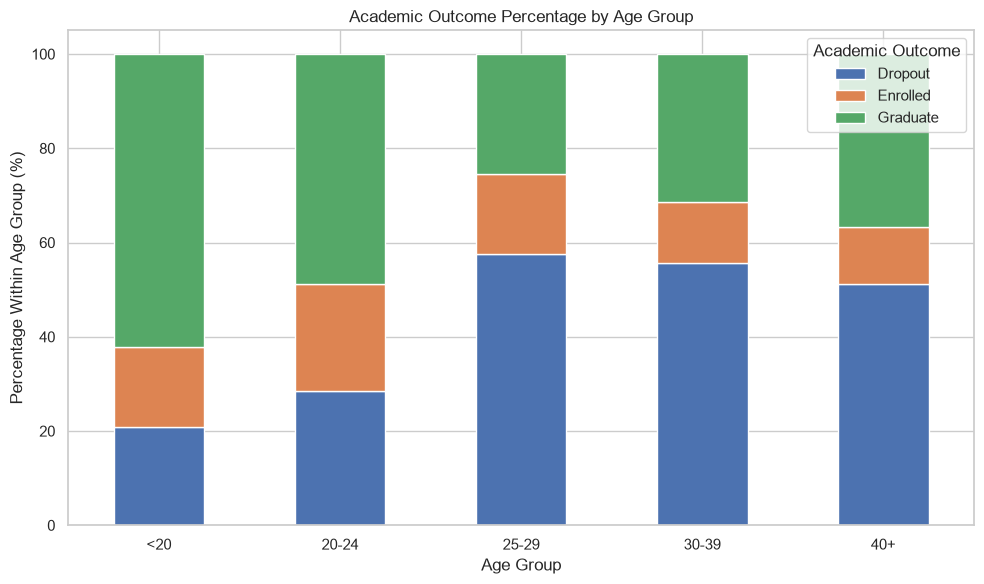

In [31]:
# Create a copy for EDA
eda_df = df.copy()

# Define age groups
age_bins = [0, 20, 25, 30, 40, 100]
age_labels = ["<20", "20-24", "25-29", "30-39", "40+"]

eda_df["Age Group"] = pd.cut(
    eda_df["Age at enrollment"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Count students in each age group
age_group_counts = eda_df["Age Group"].value_counts().sort_index()

display(age_group_counts)

# Calculate percentages within each age group
age_outcome = pd.crosstab(
    eda_df["Age Group"],
    eda_df["Target"],
    normalize="index"
) * 100

age_outcome = age_outcome.reindex(
    columns=["Dropout", "Enrolled", "Graduate"]
)

display(age_outcome.round(2))

# Visualization
age_outcome.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Academic Outcome Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage Within Age Group (%)")
plt.xticks(rotation=0)
plt.legend(title="Academic Outcome")
plt.tight_layout()
plt.show()

### Academic Outcome Analysis by Age Group

**Objective:**

To investigate how the proportions of academic outcomes vary across different age groups and determine whether student age at enrollment is associated with dropout and graduation patterns.

**Key Findings:**

- **Under 20:** This age group has the lowest observed dropout percentage (20.95%) and the highest graduation percentage (62.09%).
- **20–24:** The dropout percentage increases to 28.56%, while the graduation percentage decreases to 48.88%.
- **25–29:** This group has the highest observed dropout percentage (57.61%) and the lowest graduation percentage (25.53%).
- **30–39:** The dropout percentage remains relatively high at 55.72%, with a graduation percentage of 31.32%.
- **40+:** The dropout percentage decreases slightly to 51.21%, while the graduation percentage increases to 36.69%.

**Interpretation:**

The results reveal substantial differences in academic outcomes across age groups. Students entering higher education before age 25 have lower observed dropout percentages than those enrolling at age 25 or above.

The dropout percentage increases considerably between the 20–24 and 25–29 age groups. However, it decreases slightly in the older age groups, suggesting that the relationship between age and academic outcome may be nonlinear rather than strictly increasing.

These results describe associations within the dataset and do not establish that age directly causes academic dropout. Other factors, including academic performance, financial circumstances, and admission characteristics, may contribute to the observed differences.

**Implications for Machine Learning:**

- Age at enrollment may provide useful predictive information and should be retained as a candidate feature.
- Decision Tree and Random Forest classifiers can capture nonlinear relationships through feature-based splits.
- The original numerical age feature can be used for model training; manually created age groups are not required.
- Model evaluation should determine whether age contributes meaningfully to predictive performance.
- Differences in group sizes should be considered when interpreting age-specific outcomes.

**Conclusion:**

The age-group analysis identifies a noticeable association between age at enrollment and academic outcomes. The 25–29 age group has the highest observed dropout percentage (57.61%), while students under 20 have the highest graduation percentage (62.09%). These findings indicate that age may be a relevant predictor of student academic outcomes.

In [32]:
#Exact grade statistics
grade_summary = df.groupby("Target")[grade_col].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(grade_summary.round(2))

,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,7.26,10.93,6.03,0.0,18.00
Enrolled,794,11.13,12.00,3.68,0.0,17.00
Graduate,2209,12.64,13.00,2.70,0.0,18.88


### Descriptive Statistics of First-Semester Grades

**Objective:**

To quantitatively compare first-semester academic performance across the Dropout, Enrolled, and Graduate groups using descriptive statistical measures.

**Key Findings:**

- **Graduate:** The highest mean grade (12.64) and median grade (13.00), with the lowest standard deviation (2.70).
- **Enrolled:** An intermediate mean grade (11.13) and median grade (12.00), with a standard deviation of 3.68.
- **Dropout:** The lowest mean grade (7.26) and median grade (10.93), with the highest standard deviation (6.03).
- The Dropout group's mean is substantially lower than its median, indicating that lower-end grade observations have a strong influence on the average.
- All three groups contain a minimum recorded first-semester grade of zero.
- The observed grade ranges overlap across all three academic outcomes.

**Interpretation:**

The descriptive statistics confirm the patterns observed in the first-semester grade boxplot. Graduate students generally demonstrate higher and less variable academic performance, while dropout students exhibit lower average grades and substantially greater variability.

The large difference between the mean and median within the Dropout group suggests a concentration of low-grade observations, potentially including zero-grade records.

However, descriptive differences do not establish a causal relationship between academic grades and student outcomes.

**Implications for Machine Learning:**

- First-semester grades should be retained as a candidate predictive feature.
- Decision Tree and Random Forest models can learn nonlinear relationships and grade-based thresholds.
- Zero-grade observations require further investigation before any preprocessing decisions are made.
- The overlap between class distributions suggests that additional academic, demographic, and financial features may be necessary for effective classification.
- Model performance should be evaluated using held

In [33]:
#Investigate zero-grade records
zero_grade_summary = df.groupby("Target")[grade_col].agg(
    Zero_Grade_Count=lambda x: (x == 0).sum(),
    Total_Students="count"
)

zero_grade_summary["Zero_Grade_Percentage"] = (
    zero_grade_summary["Zero_Grade_Count"]
    / zero_grade_summary["Total_Students"]
    * 100
)

display(zero_grade_summary.round(2))

,Zero_Grade_Count,Total_Students,Zero_Grade_Percentage
Target,,,
Dropout,570,1421,40.11
Enrolled,71,794,8.94
Graduate,77,2209,3.49


### Investigation of Zero First-Semester Grades

**Objective:**

To investigate the frequency of zero-grade observations across academic outcome classes and assess their possible contribution to differences in first-semester grade distributions.

**Key Findings:**

- **Dropout:** 570 out of 1,421 students (40.11%) have a recorded first-semester grade of zero.
- **Enrolled:** 71 out of 794 students (8.94%) have a zero grade.
- **Graduate:** 77 out of 2,209 students (3.49%) have a zero grade.
- Overall, 718 out of 4,424 students (16.23%) have a recorded first-semester grade of zero.
- Zero-grade observations are substantially more common in the Dropout class than in the other academic outcome classes.

**Interpretation:**

The high proportion of zero-grade observations among dropout students helps explain the substantial difference between their mean first-semester grade (7.26) and median grade (10.93), as identified in the previous analysis.

The findings indicate a strong descriptive association between zero first-semester grades and academic outcomes. However, this analysis does not establish that zero grades cause students to drop out.

The precise meaning of a recorded zero grade has not yet been established. It may reflect academic performance or other circumstances associated with students' curricular activity. Further investigation is required before assigning a specific interpretation.

**Implications for Machine Learning:**

- Zero-grade records should not automatically be removed or treated as missing values.
- First-semester grades may provide useful predictive information for distinguishing academic outcomes.
- The relationship between zero grades and approved curricular units should be investigated to better understand the recorded values.
- Decision Tree and Random Forest models can learn thresholds that distinguish zero and nonzero grade observations.
- First-semester grades should only be used when they would be available at the intended time of prediction, preventing temporal data leakage.

**Conclusion:**

Zero first-semester grades are substantially more prevalent among dropout students (40.11%) than among enrolled (8.94%) or graduate students (3.49%). This pattern contributes to the lower average grade observed in the Dropout group and suggests that first-semester academic performance may be relevant for predicting academic outcomes. However, further investigation is necessary to understand the meaning of zero-grade records before making preprocessing decisions.

In [34]:
zero_grade_students = df[df[grade_col] == 0]

approved_units_summary = zero_grade_students.groupby("Target")[
    "Curricular units 1st sem (approved)"
].agg(
    ["count", "mean", "median", "min", "max"]
)

display(approved_units_summary.round(2))

,count,mean,median,min,max
Target,,,,,
Dropout,570,0.0,0.0,0,0
Enrolled,71,0.0,0.0,0,0
Graduate,77,0.0,0.0,0,0


### Relationship Between Zero Grades and Approved Curricular Units

**Objective:**

To investigate whether students with a recorded first-semester grade of zero have successfully completed any first-semester curricular units, and to assess the implications of these observations for data preprocessing.

**Key Findings:**

- A total of **718 students** have a recorded first-semester grade of zero.
- Among these students, 570 belong to the Dropout class, 71 to the Enrolled class, and 77 to the Graduate class.
- All 718 students with zero first-semester grades also have **zero approved first-semester curricular units**.
- The mean, median, minimum, and maximum number of approved units are all zero across the three academic outcome groups.

**Interpretation:**

The findings demonstrate that every student with a recorded first-semester grade of zero also has no approved first-semester curricular units.

This suggests that zero-grade observations may reflect a lack of successful academic progression during the first semester rather than being random data-entry errors.

However, the analysis does not establish whether these students failed their assessments, did not participate in assessments, or experienced other academic circumstances.

The observed relationship is directional: all zero-grade records have zero approved units. The reverse relationship has not yet been verified.

**Implications for Machine Learning:**

- Zero-grade observations should be retained unless further evidence indicates that they are invalid.
- Both first-semester grade and approved-unit count are potentially informative academic performance features.
- These features may contain overlapping information, which should be examined during correlation analysis and model evaluation.
- Decision Tree and Random Forest models can learn relationships between grades, approved units, and academic outcomes.
- Both variables must be available at the intended prediction time to avoid temporal data leakage.

**Conclusion:**

All 718 students with zero first-semester grades also have zero approved curricular units. This finding strengthens the evidence that zero-grade observations are associated with recorded academic progress. Therefore, these values should not automatically be treated as missing or erroneous during preprocessing.

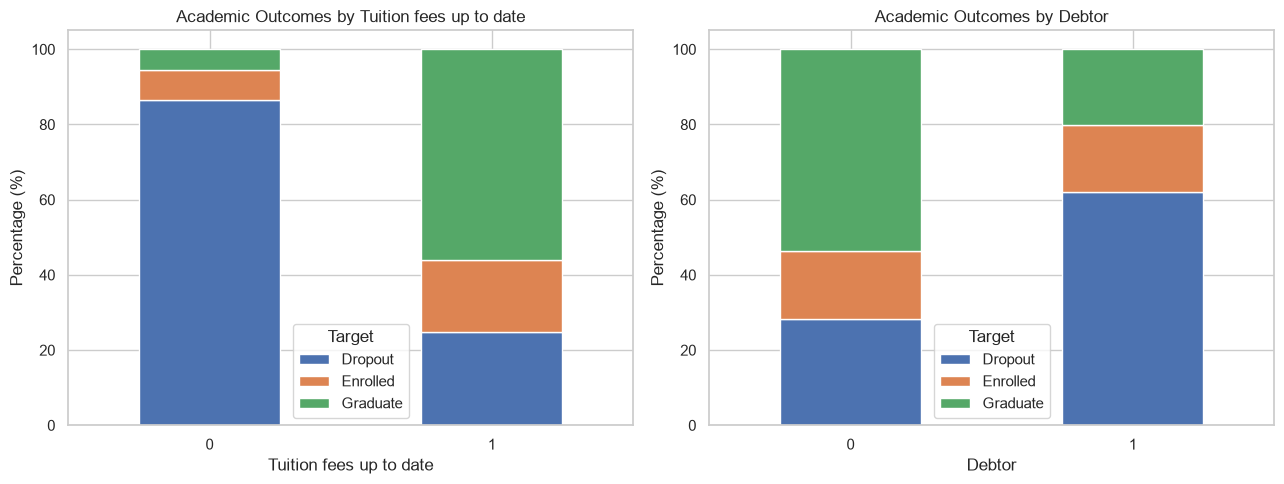

In [35]:
#Financial factors vs academic outcome
financial_features = [
    "Tuition fees up to date",
    "Debtor"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, financial_features):
    percentage_table = pd.crosstab(
        df[feature],
        df["Target"],
        normalize="index"
    ) * 100

    percentage_table = percentage_table.reindex(
        columns=["Dropout", "Enrolled", "Graduate"]
    )

    percentage_table.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Academic Outcomes by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Financial Factors and Academic Outcomes

**Objective:**

To investigate the association between students' financial indicators and their academic outcomes, focusing on tuition fee payment status and debtor status.

**Key Findings:**

**1. Tuition Fee Payment Status**

- Students whose tuition fees are not up to date (`0`) exhibit a substantially higher proportion of dropout outcomes (approximately 86%).
- Students whose tuition fees are up to date (`1`) have a considerably lower dropout proportion (approximately 25%).
- The proportion of graduates is noticeably higher among students whose tuition fees are up to date.

**2. Debtor Status**

- Students recorded as debtors (`1`) exhibit a higher dropout proportion (approximately 62%) than students not recorded as debtors (`0`, approximately 28%).
- Non-debtor students have a higher proportion of graduates (approximately 54%) compared with debtor students (approximately 20%).
- The proportions of students remaining enrolled appear relatively similar between the two debtor categories.

*The percentages above are approximate visual estimates and should be verified using numerical cross-tabulations.*

**Interpretation:**

Both financial indicators demonstrate noticeable associations with academic outcomes. Students with unpaid or outdated tuition fee status and those recorded as debtors are more frequently represented in the Dropout category.

These findings suggest that financial circumstances or related administrative conditions may be associated with academic progression. However, the observed relationships do not establish causation.

The timing of financial status measurements must also be considered, since these indicators may change during a student's academic journey.

**Implications for Machine Learning:**

- `Tuition fees up to date` and `Debtor` are potentially informative binary predictors.
- Both features can be used directly as binary inputs for Decision Tree and Random Forest classifiers.
- Their predictive contributions should be evaluated using held-out data.
- The measurement timing of these indicators should be verified to prevent temporal data leakage.
- The class distribution within each financial category should be considered alongside its sample size.

**Conclusion:**

The analysis indicates substantial differences in academic outcomes according to tuition fee payment status and debtor status. Both variables may contribute useful predictive information, although their predictive value and temporal suitability must be assessed during model development.

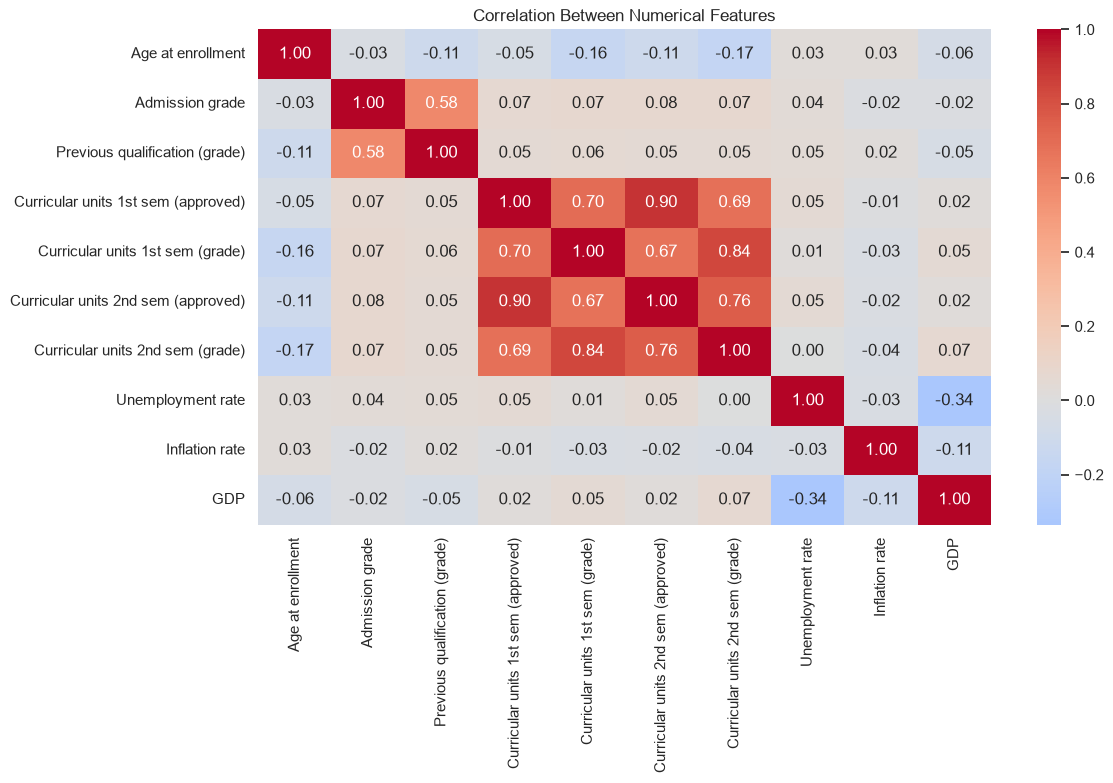

In [36]:
#Numerical feature correlation
numerical_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

### Correlation Analysis of Numerical Features

**Objective:**

To examine linear relationships among selected numerical features, identify strongly correlated variables, and understand potential feature redundancy before model development.

**Key Findings:**

The Pearson correlation matrix reveals several notable relationships:

- **First-semester approved units and second-semester approved units (r = 0.90):** A very strong positive correlation, indicating that students who successfully complete more curricular units in the first semester tend to complete more units in the second semester.
- **First-semester grades and second-semester grades (r = 0.84):** A strong positive relationship, suggesting consistency in recorded academic performance across semesters.
- **Second-semester approved units and second-semester grades (r = 0.76):** A strong positive association between academic grades and successfully completed curricular units.
- **First-semester approved units and first-semester grades (r = 0.70):** A strong positive relationship between grades and approved curricular units.
- **Admission grade and previous qualification grade (r = 0.58):** A moderate positive correlation between previous academic qualifications and university admission grades.
- **Unemployment rate and GDP (r = -0.34):** A moderate negative linear relationship.
- **Age at enrollment and first-semester grade (r = -0.16):** A weak negative linear relationship.
- **Age at enrollment and second-semester grade (r = -0.17):** A weak negative linear relationship.

**Interpretation:**

The strongest correlations occur among academic performance variables, particularly grades and approved curricular units across the first and second semesters.

These findings suggest that students' recorded academic performance across semesters contains related information. The observed correlations also indicate possible redundancy among some numerical predictors.

However, correlation does not imply causation. Furthermore, Pearson correlation measures linear relationships and may not fully capture nonlinear associations.

This correlation matrix examines relationships among predictors rather than their direct relationships with the target variable.

**Implications for Machine Learning:**

- Academic performance variables should be considered as candidate predictors due to their potential relevance to student outcomes.
- Highly correlated features may contain overlapping predictive information; however, they should not be automatically removed.
- Decision Tree and Random Forest classifiers can handle correlated numerical predictors, although correlation may complicate feature importance interpretation.
- The usefulness of individual predictors should be assessed through validation-based feature importance or feature selection experiments.
- Feature availability at the intended prediction time must be verified to prevent temporal data leakage.
- The original numerical features can be retained for the initial tree-based models without mandatory feature scaling.

**Conclusion:**

The correlation analysis identifies strong positive associations among first- and second-semester academic performance variables. Moderate relationships are also observed between admission and previous qualification grades. These findings provide insight into the structure of the dataset and identify potential feature redundancy that can be examined during model development.

## Final Exploratory Data Analysis Summary

The Exploratory Data Analysis (EDA) was conducted to understand the dataset, identify important patterns, and prepare for machine learning model development.

### Key Findings

1. **Dataset Quality:** The dataset contains 4,424 student records, 36 input features, and 3 target classes. No missing values or duplicate records were identified.

2. **Class Imbalance:** Graduate students represent 49.93% of the dataset, followed by Dropout (32.12%) and Enrolled (17.95%). This indicates class imbalance.

3. **Age and Academic Outcomes:** Students under 20 have the highest graduation percentage (62.09%), while students aged 25–29 have the highest dropout percentage (57.61%). Age may therefore provide useful predictive information.

4. **Academic Performance:** Graduate students have higher average first-semester grades (12.64) than Enrolled (11.13) and Dropout students (7.26).

5. **Zero-Grade Analysis:** Approximately 40.11% of dropout students have zero first-semester grades. All 718 students with zero grades also have zero approved first-semester curricular units. These values should not automatically be considered missing or invalid.

6. **Financial Factors:** Students with tuition fees not up to date or recorded debtor status show higher dropout proportions, suggesting an association between financial indicators and academic outcomes.

7. **Feature Correlation:** Strong positive correlations exist between first- and second-semester approved units (0.90) and grades (0.84), indicating potentially overlapping academic performance information.

### Implications for Machine Learning

- Use a stratified train-test split to maintain target class proportions.
- Evaluate models using accuracy, precision, recall, macro F1-score, and confusion matrices.
- Retain meaningful numerical features and investigate categorical feature encoding.
- Preserve valid zero-grade observations.
- Prevent data leakage by using only features available at the intended prediction time.
- Compare Decision Tree and Random Forest classifiers using consistent evaluation methods.

### Conclusion

The EDA indicates that academic performance, age, and financial indicators are associated with student academic outcomes. These findings provide a foundation for preprocessing, feature selection, and machine learning model development. However, the predictive importance of these features must be validated through model training and evaluation.